
# SmartServe — Business Intelligence and Decision Support

## Project Overview

This notebook transforms SmartServe's demand forecasting and inventory recommendation outputs into business intelligence insights to support data-driven decision-making.

It focuses on analyzing historical demand predictions, evaluating store and product performance, and translating forecasting results into practical inventory planning recommendations.

## Business Objective

Develop a business intelligence reporting layer that enables management to monitor demand patterns, evaluate forecasting performance, compare store and product performance, and make informed inventory planning decisions.

## Key Objectives

- Analyze historical actual demand against model predictions.
- Evaluate forecasting performance across stores and products.
- Identify overprediction and underprediction patterns.
- Compare demand and forecasting accuracy across business segments.
- Analyze preliminary safety stock and recommended stock levels.
- Develop actionable business insights for operational decision-making.
- Prepare structured datasets for Power BI and Excel reporting.

## Business Intelligence Sections

### 1. Data Loading and Initialization
Load the validated deployment datasets and establish the business intelligence environment.

### 2. Data Structure and Validation
Inspect dataset dimensions, columns, data types, missing values, and data consistency.

### 3. Executive Business KPIs
Calculate key business indicators covering historical demand, predictions, and forecasting performance.

### 4. Historical Demand Analysis
Analyze actual and predicted demand patterns over time.

### 5. Forecasting Performance Analysis
Evaluate prediction errors, forecast bias, MAE, RMSE, and R².

### 6. Store Performance Analysis
Compare demand and forecasting accuracy across individual stores.

### 7. Product Performance Analysis
Identify high-demand products, low-demand products, and products with significant forecasting errors.

### 8. Inventory Decision Support
Analyze average predicted demand, preliminary safety stock, and recommended stock levels.

### 9. Business Insights and Recommendations
Translate analytical findings into practical recommendations for management.

### 10. Power BI Reporting Dataset Preparation
Prepare clean, structured datasets for interactive business intelligence dashboards.

### 11. Export and Validation
Export and validate the final business intelligence datasets.

## Expected Deliverables

- Executive KPI summary
- Historical demand analysis
- Store performance analysis
- Product performance analysis
- Forecast accuracy analysis
- Inventory decision-support analysis
- Business recommendations
- Power BI-ready reporting datasets

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Power BI
- Excel

## Important Analytical Note

The forecasting results analyzed in this notebook represent historical predictions across the available 90-day dataset. They should not be interpreted as independently validated future demand forecasts.

Inventory recommendations are preliminary analytical estimates and require operational validation before implementation.

## Final Outcome

A structured business intelligence layer that connects demand forecasting outputs with operational performance analysis and inventory decision support.


In [2]:

# Section 1: Initialize Business Intelligence Notebook

from pathlib import Path
import sys
import pandas as pd
import numpy as np

# Identify project root.
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import reusable BI module.
from src.business_intelligence import load_bi_datasets

# Load validated deployment datasets.
bi_datasets = load_bi_datasets(PROJECT_ROOT)

forecast_results = bi_datasets["forecast_results"]
store_performance = bi_datasets["store_performance"]
product_performance = bi_datasets["product_performance"]
inventory_recommendations = bi_datasets["inventory_recommendations"]

print("SMARTSERVE — BUSINESS INTELLIGENCE INITIALIZATION")
print("=" * 70)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nHistorical Forecast Results:", forecast_results.shape)
print("Store Performance:", store_performance.shape)
print("Product Performance:", product_performance.shape)
print("Inventory Recommendations:", inventory_recommendations.shape)

print("\nBusiness Intelligence datasets loaded successfully.")


SMARTSERVE — BUSINESS INTELLIGENCE INITIALIZATION

Project root:
d:\Data Analysis Projects\SmartServe-Food-Intelligence

Historical Forecast Results: (9000, 6)
Store Performance: (5, 10)
Product Performance: (20, 10)
Inventory Recommendations: (100, 8)

Business Intelligence datasets loaded successfully.


In [3]:

# Section 2: Inspect Business Intelligence Datasets

for dataset_name, dataset in bi_datasets.items():

    print("\n" + "=" * 75)
    print(dataset_name.upper().replace("_", " "))
    print("=" * 75)

    print("\nDataset shape:")
    print(dataset.shape)

    print("\nColumn names:")
    print(dataset.columns.tolist())

    print("\nData types:")
    print(dataset.dtypes)

    print("\nMissing values:")
    print(dataset.isna().sum())

    print("\nDuplicate rows:")
    print(dataset.duplicated().sum())

print("\nBUSINESS INTELLIGENCE DATA INSPECTION COMPLETED")



FORECAST RESULTS

Dataset shape:
(9000, 6)

Column names:
['date_id', 'full_date', 'store_id', 'product_id', 'actual_sales_qty', 'predicted_sales_qty']

Data types:
date_id                         int64
full_date              datetime64[us]
store_id                          str
product_id                        str
actual_sales_qty                int64
predicted_sales_qty             int64
dtype: object

Missing values:
date_id                0
full_date              0
store_id               0
product_id             0
actual_sales_qty       0
predicted_sales_qty    0
dtype: int64

Duplicate rows:
0

STORE PERFORMANCE

Dataset shape:
(5, 10)

Column names:
['store_id', 'total_records', 'actual_demand', 'predicted_demand', 'average_actual_demand', 'average_predicted_demand', 'mean_absolute_error', 'mean_prediction_error', 'demand_difference', 'demand_difference_pct']

Data types:
store_id                        str
total_records                 int64
actual_demand                 int64


In [4]:

# Section 2B: Inspect Remaining BI Datasets

remaining_datasets = {
    "Store Performance": store_performance,
    "Product Performance": product_performance,
    "Inventory Recommendations": inventory_recommendations
}

for dataset_name, dataset in remaining_datasets.items():

    print("\n" + "=" * 75)
    print(dataset_name.upper())
    print("=" * 75)

    print("\nShape:", dataset.shape)

    print("\nColumns:")
    print(dataset.columns.tolist())

    print("\nData types:")
    print(dataset.dtypes)

    print("\nMissing values:")
    print(dataset.isna().sum())

    print("\nDuplicate rows:")
    print(dataset.duplicated().sum())

print("\nREMAINING DATASET INSPECTION COMPLETED")



STORE PERFORMANCE

Shape: (5, 10)

Columns:
['store_id', 'total_records', 'actual_demand', 'predicted_demand', 'average_actual_demand', 'average_predicted_demand', 'mean_absolute_error', 'mean_prediction_error', 'demand_difference', 'demand_difference_pct']

Data types:
store_id                        str
total_records                 int64
actual_demand                 int64
predicted_demand              int64
average_actual_demand       float64
average_predicted_demand    float64
mean_absolute_error         float64
mean_prediction_error       float64
demand_difference             int64
demand_difference_pct       float64
dtype: object

Missing values:
store_id                    0
total_records               0
actual_demand               0
predicted_demand            0
average_actual_demand       0
average_predicted_demand    0
mean_absolute_error         0
mean_prediction_error       0
demand_difference           0
demand_difference_pct       0
dtype: int64

Duplicate rows:
0

PROD

In [5]:

# Section 2C: Inspect Product and Inventory Datasets

for dataset_name, dataset in {
    "Product Performance": product_performance,
    "Inventory Recommendations": inventory_recommendations
}.items():

    print("\n" + "=" * 75)
    print(dataset_name.upper())
    print("=" * 75)

    print("\nShape:", dataset.shape)

    print("\nColumns:")
    print(dataset.columns.tolist())

    print("\nData types:")
    print(dataset.dtypes)

    print("\nMissing values:")
    print(dataset.isna().sum().to_string())

    print("\nDuplicate rows:")
    print(dataset.duplicated().sum())

print("\nPRODUCT AND INVENTORY INSPECTION COMPLETED")



PRODUCT PERFORMANCE

Shape: (20, 10)

Columns:
['product_id', 'total_records', 'actual_demand', 'predicted_demand', 'average_actual_demand', 'average_predicted_demand', 'mean_absolute_error', 'mean_prediction_error', 'demand_difference', 'demand_difference_pct']

Data types:
product_id                      str
total_records                 int64
actual_demand                 int64
predicted_demand              int64
average_actual_demand       float64
average_predicted_demand    float64
mean_absolute_error         float64
mean_prediction_error       float64
demand_difference             int64
demand_difference_pct       float64
dtype: object

Missing values:
product_id                  0
total_records               0
actual_demand               0
predicted_demand            0
average_actual_demand       0
average_predicted_demand    0
mean_absolute_error         0
mean_prediction_error       0
demand_difference           0
demand_difference_pct       0

Duplicate rows:
0

INVENTORY RE

In [6]:

# Section 2D: Inspect Inventory Recommendations

print("=" * 75)
print("INVENTORY RECOMMENDATIONS")
print("=" * 75)

print("\nDataset shape:")
print(inventory_recommendations.shape)

print("\nColumns:")
print(inventory_recommendations.columns.tolist())

print("\nData types:")
print(inventory_recommendations.dtypes)

print("\nMissing values:")
print(inventory_recommendations.isna().sum().to_string())

print("\nDuplicate rows:")
print(inventory_recommendations.duplicated().sum())

print("\nSample records:")
print(inventory_recommendations.head(10).to_string(index=False))

print("\nINVENTORY DATASET INSPECTION COMPLETED")


INVENTORY RECOMMENDATIONS

Dataset shape:
(100, 8)

Columns:
['store_id', 'product_id', 'average_daily_demand', 'maximum_predicted_demand', 'average_underprediction', 'underprediction_std', 'safety_stock', 'recommended_stock']

Data types:
store_id                        str
product_id                      str
average_daily_demand        float64
maximum_predicted_demand      int64
average_underprediction     float64
underprediction_std         float64
safety_stock                float64
recommended_stock             int64
dtype: object

Missing values:
store_id                    0
product_id                  0
average_daily_demand        0
maximum_predicted_demand    0
average_underprediction     0
underprediction_std         0
safety_stock                0
recommended_stock           0

Duplicate rows:
0

Sample records:
store_id product_id  average_daily_demand  maximum_predicted_demand  average_underprediction  underprediction_std  safety_stock  recommended_stock
   ST001     PRD00

In [7]:

# Section 3: Calculate Executive Business KPIs

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Historical actual and predicted demand.
actual_demand = forecast_results["actual_sales_qty"]
predicted_demand = forecast_results["predicted_sales_qty"]

# Demand KPIs.
total_actual_demand = actual_demand.sum()
total_predicted_demand = predicted_demand.sum()

average_actual_demand = actual_demand.mean()
average_predicted_demand = predicted_demand.mean()

total_demand_difference = (
    total_predicted_demand - total_actual_demand
)

demand_difference_pct = (
    total_demand_difference / total_actual_demand
) * 100

# Forecasting performance KPIs.
forecast_mae = mean_absolute_error(
    actual_demand,
    predicted_demand
)

forecast_rmse = np.sqrt(
    mean_squared_error(
        actual_demand,
        predicted_demand
    )
)

forecast_r2 = r2_score(
    actual_demand,
    predicted_demand
)

# Forecast bias.
mean_prediction_error = (
    predicted_demand - actual_demand
).mean()

# Coverage KPIs.
total_stores = forecast_results["store_id"].nunique()
total_products = forecast_results["product_id"].nunique()
total_records = len(forecast_results)

# Inventory KPIs.
total_store_product_combinations = len(
    inventory_recommendations
)

average_recommended_stock = (
    inventory_recommendations["recommended_stock"].mean()
)

average_safety_stock = (
    inventory_recommendations["safety_stock"].mean()
)

# Create executive KPI table.
executive_kpis = pd.DataFrame({
    "KPI": [
        "Total Actual Demand",
        "Total Predicted Demand",
        "Average Actual Daily Demand per Record",
        "Average Predicted Daily Demand per Record",
        "Total Demand Difference",
        "Demand Difference Percentage",
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R-squared",
        "Mean Prediction Error",
        "Number of Stores",
        "Number of Products",
        "Historical Prediction Records",
        "Store-Product Inventory Combinations",
        "Average Recommended Stock",
        "Average Safety Stock"
    ],
    "Value": [
        total_actual_demand,
        total_predicted_demand,
        average_actual_demand,
        average_predicted_demand,
        total_demand_difference,
        demand_difference_pct,
        forecast_mae,
        forecast_rmse,
        forecast_r2,
        mean_prediction_error,
        total_stores,
        total_products,
        total_records,
        total_store_product_combinations,
        average_recommended_stock,
        average_safety_stock
    ]
})

print("SMARTSERVE — EXECUTIVE BUSINESS KPI SUMMARY")
print("=" * 75)

print(
    executive_kpis.to_string(
        index=False,
        formatters={
            "Value": lambda value: f"{value:,.2f}"
        }
    )
)

print("\nEXECUTIVE KPI CALCULATION COMPLETED")


SMARTSERVE — EXECUTIVE BUSINESS KPI SUMMARY
                                      KPI      Value
                      Total Actual Demand 296,663.00
                   Total Predicted Demand 298,009.00
   Average Actual Daily Demand per Record      32.96
Average Predicted Daily Demand per Record      33.11
                  Total Demand Difference   1,346.00
             Demand Difference Percentage       0.45
                Mean Absolute Error (MAE)       8.21
           Root Mean Squared Error (RMSE)      10.61
                                R-squared       0.62
                    Mean Prediction Error       0.15
                         Number of Stores       5.00
                       Number of Products      20.00
            Historical Prediction Records   9,000.00
     Store-Product Inventory Combinations     100.00
                Average Recommended Stock      43.92
                     Average Safety Stock      10.28

EXECUTIVE KPI CALCULATION COMPLETED


In [9]:

# Refresh the business intelligence module

import importlib
import src.business_intelligence as bi

importlib.reload(bi)

# Import the newly added function
prepare_daily_demand_analysis = bi.prepare_daily_demand_analysis

print("Business intelligence module reloaded successfully.")
print("Function available:", callable(prepare_daily_demand_analysis))


Business intelligence module reloaded successfully.
Function available: True


In [10]:

# Section 4.1: Generate Daily Demand Analysis

from src.business_intelligence import prepare_daily_demand_analysis

daily_demand = prepare_daily_demand_analysis(
    forecast_results
)

print("SMARTSERVE — DAILY DEMAND ANALYSIS")
print("=" * 75)

print("\nDataset shape:")
print(daily_demand.shape)

print("\nColumns:")
print(daily_demand.columns.tolist())

print("\nDate range:")
print(
    daily_demand["full_date"].min(),
    "to",
    daily_demand["full_date"].max()
)

print("\nDaily demand summary:")
print(
    daily_demand[
        ["actual_demand", "predicted_demand"]
    ].describe().round(2)
)

print("\nFirst 10 records:")
print(daily_demand.head(10).to_string(index=False))

print("\nDAILY DEMAND ANALYSIS COMPLETED")


SMARTSERVE — DAILY DEMAND ANALYSIS

Dataset shape:
(90, 6)

Columns:
['full_date', 'actual_demand', 'predicted_demand', 'prediction_error', 'actual_7day_avg', 'predicted_7day_avg']

Date range:
2025-01-01 00:00:00 to 2025-03-31 00:00:00

Daily demand summary:
       actual_demand  predicted_demand
count          90.00             90.00
mean         3296.26           3311.21
std           314.03            281.01
min          2913.00           2954.00
25%          3075.00           3149.00
50%          3151.00           3187.00
75%          3599.00           3467.00
max          3985.00           3909.00

First 10 records:
 full_date  actual_demand  predicted_demand  prediction_error  actual_7day_avg  predicted_7day_avg
2025-01-01           3137              3148                11      3137.000000         3148.000000
2025-01-02           2922              3153               231      3029.500000         3150.500000
2025-01-03           3075              3155                80      3044.6

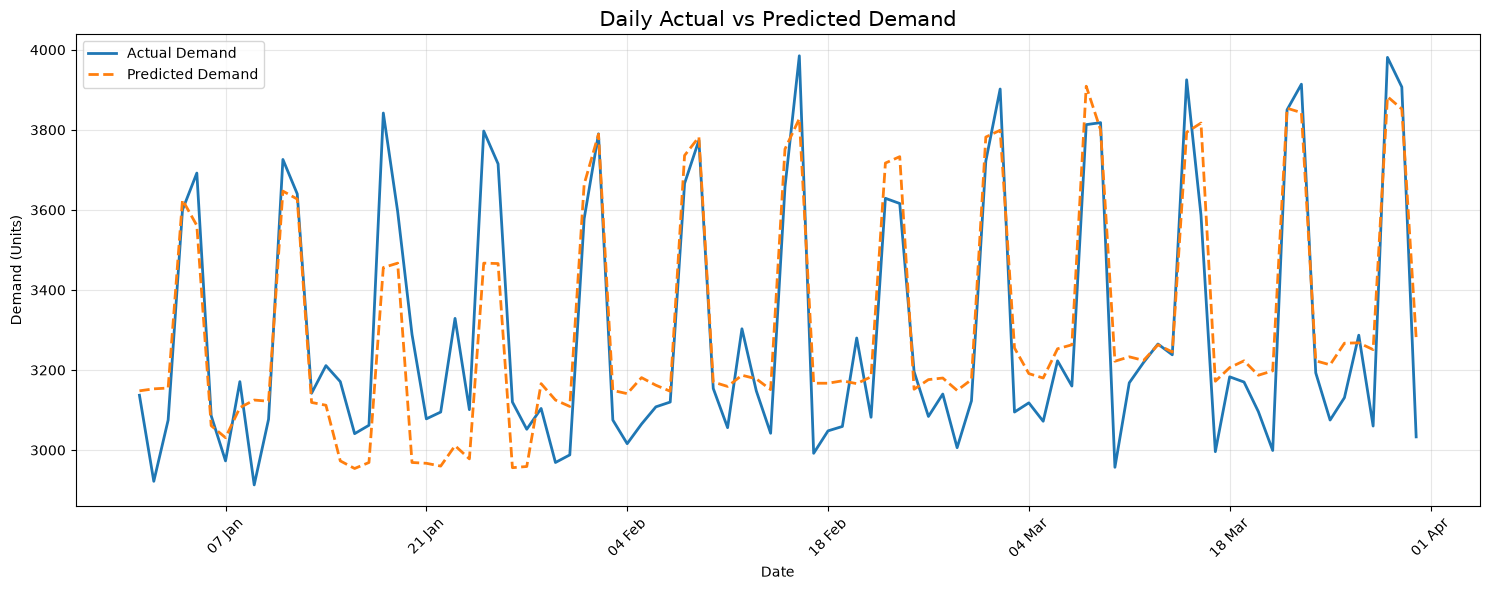

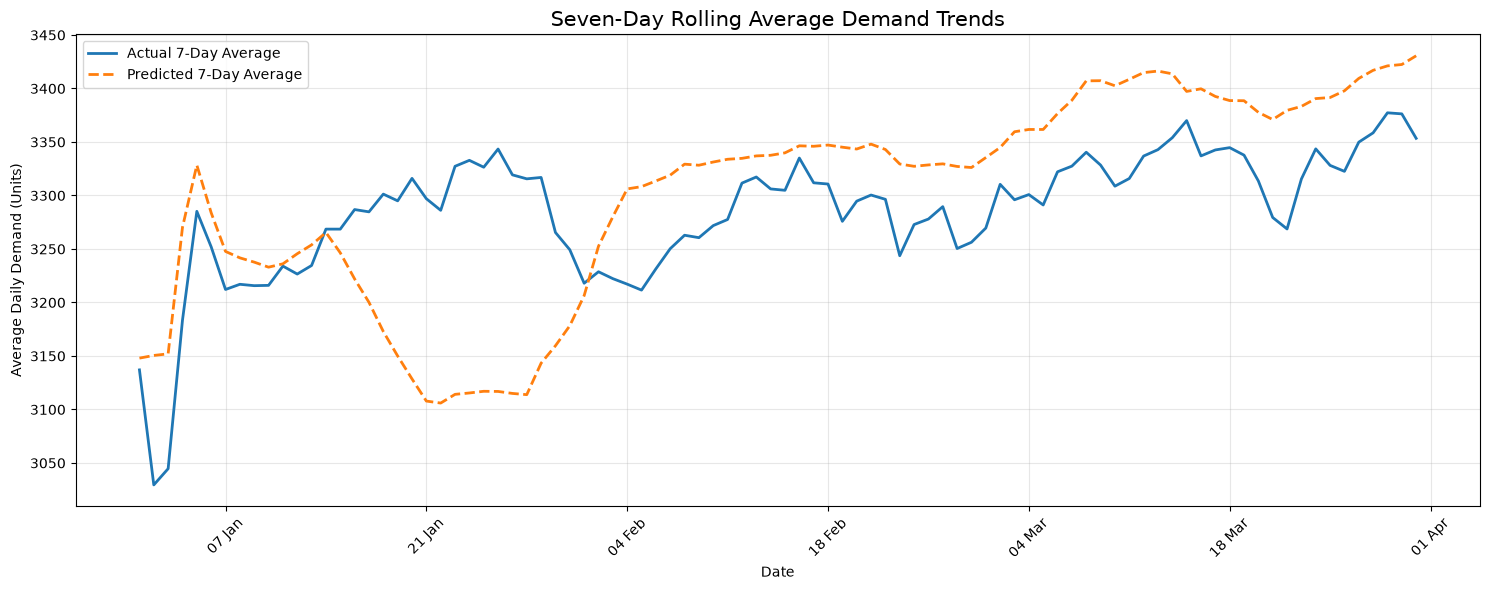

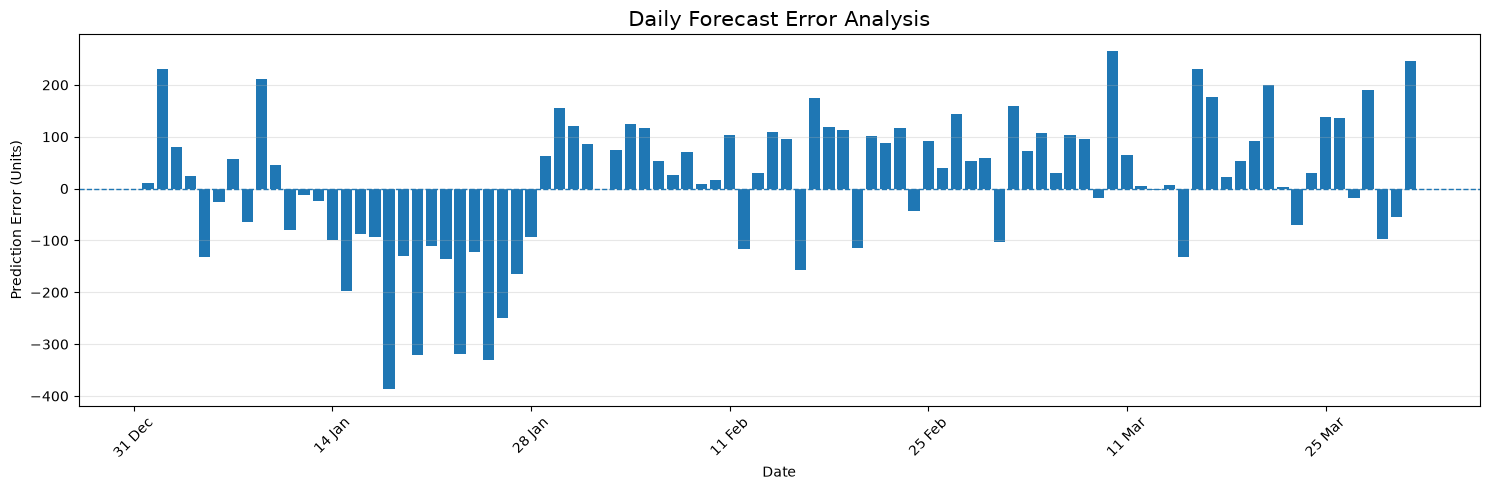

HISTORICAL DEMAND VISUALIZATION COMPLETED


In [11]:

# Section 4.2: Visualize Historical Demand Trends

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# Visualization 1: Actual vs Predicted Daily Demand
# --------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["full_date"],
    daily_demand["actual_demand"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    daily_demand["full_date"],
    daily_demand["predicted_demand"],
    label="Predicted Demand",
    linewidth=2,
    linestyle="--"
)

plt.title(
    "Daily Actual vs Predicted Demand",
    fontsize=15
)
plt.xlabel("Date")
plt.ylabel("Demand (Units)")
plt.legend()
plt.grid(alpha=0.3)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)
plt.gca().xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Seven-Day Rolling Average
# --------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["full_date"],
    daily_demand["actual_7day_avg"],
    label="Actual 7-Day Average",
    linewidth=2
)

plt.plot(
    daily_demand["full_date"],
    daily_demand["predicted_7day_avg"],
    label="Predicted 7-Day Average",
    linewidth=2,
    linestyle="--"
)

plt.title(
    "Seven-Day Rolling Average Demand Trends",
    fontsize=15
)
plt.xlabel("Date")
plt.ylabel("Average Daily Demand (Units)")
plt.legend()
plt.grid(alpha=0.3)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)
plt.gca().xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 3: Daily Prediction Errors
# --------------------------------------------------

plt.figure(figsize=(15, 5))

plt.bar(
    daily_demand["full_date"],
    daily_demand["prediction_error"],
    width=0.8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Daily Forecast Error Analysis",
    fontsize=15
)
plt.xlabel("Date")
plt.ylabel("Prediction Error (Units)")
plt.grid(axis="y", alpha=0.3)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)
plt.gca().xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("HISTORICAL DEMAND VISUALIZATION COMPLETED")


In [12]:

# Section 4.3: Daily Demand Pattern Analysis

# Identify peak and lowest demand dates
peak_demand_day = daily_demand.loc[
    daily_demand["actual_demand"].idxmax()
]

lowest_demand_day = daily_demand.loc[
    daily_demand["actual_demand"].idxmin()
]

# Identify largest overprediction and underprediction
largest_overprediction = daily_demand.loc[
    daily_demand["prediction_error"].idxmax()
]

largest_underprediction = daily_demand.loc[
    daily_demand["prediction_error"].idxmin()
]

# Calculate daily error statistics
daily_error_summary = {
    "Average Daily Prediction Error": (
        daily_demand["prediction_error"].mean()
    ),
    "Average Absolute Daily Error": (
        daily_demand["prediction_error"].abs().mean()
    ),
    "Maximum Overprediction": (
        daily_demand["prediction_error"].max()
    ),
    "Maximum Underprediction": (
        daily_demand["prediction_error"].min()
    ),
    "Days with Overprediction": (
        daily_demand["prediction_error"].gt(0).sum()
    ),
    "Days with Underprediction": (
        daily_demand["prediction_error"].lt(0).sum()
    ),
    "Days with Exact Prediction": (
        daily_demand["prediction_error"].eq(0).sum()
    )
}

print("SMARTSERVE — DAILY DEMAND PATTERN ANALYSIS")
print("=" * 75)

print("\nPEAK ACTUAL DEMAND")
print("Date:", peak_demand_day["full_date"].date())
print("Actual demand:", peak_demand_day["actual_demand"])
print("Predicted demand:", peak_demand_day["predicted_demand"])

print("\nLOWEST ACTUAL DEMAND")
print("Date:", lowest_demand_day["full_date"].date())
print("Actual demand:", lowest_demand_day["actual_demand"])
print("Predicted demand:", lowest_demand_day["predicted_demand"])

print("\nLARGEST OVERPREDICTION")
print("Date:", largest_overprediction["full_date"].date())
print("Prediction error:", largest_overprediction["prediction_error"])

print("\nLARGEST UNDERPREDICTION")
print("Date:", largest_underprediction["full_date"].date())
print("Prediction error:", largest_underprediction["prediction_error"])

print("\nDAILY ERROR SUMMARY")
for metric, value in daily_error_summary.items():
    print(f"{metric}: {value:,.2f}")

print("\nDAILY DEMAND PATTERN ANALYSIS COMPLETED")


SMARTSERVE — DAILY DEMAND PATTERN ANALYSIS

PEAK ACTUAL DEMAND
Date: 2025-02-16
Actual demand: 3985
Predicted demand: 3828

LOWEST ACTUAL DEMAND
Date: 2025-01-09
Actual demand: 2913
Predicted demand: 3125

LARGEST OVERPREDICTION
Date: 2025-03-10
Prediction error: 265

LARGEST UNDERPREDICTION
Date: 2025-01-18
Prediction error: -386

DAILY ERROR SUMMARY
Average Daily Prediction Error: 14.96
Average Absolute Daily Error: 106.07
Maximum Overprediction: 265.00
Maximum Underprediction: -386.00
Days with Overprediction: 56.00
Days with Underprediction: 34.00
Days with Exact Prediction: 0.00

DAILY DEMAND PATTERN ANALYSIS COMPLETED


In [13]:

# Section 5.1: Forecast Error Analysis

forecast_error_analysis = forecast_results.copy()

forecast_error_analysis["prediction_error"] = (
    forecast_error_analysis["predicted_sales_qty"]
    - forecast_error_analysis["actual_sales_qty"]
)

forecast_error_analysis["absolute_error"] = (
    forecast_error_analysis["prediction_error"].abs()
)

forecast_error_analysis["error_type"] = np.select(
    [
        forecast_error_analysis["prediction_error"] > 0,
        forecast_error_analysis["prediction_error"] < 0
    ],
    [
        "Overprediction",
        "Underprediction"
    ],
    default="Exact Prediction"
)

print("SMARTSERVE — FORECAST ERROR ANALYSIS")
print("=" * 75)

print("\nDataset shape:")
print(forecast_error_analysis.shape)

print("\nError type distribution:")
print(
    forecast_error_analysis["error_type"]
    .value_counts()
    .to_string()
)

print("\nForecast error statistics:")
print(
    forecast_error_analysis[
        ["prediction_error", "absolute_error"]
    ].describe().round(2)
)

print("\nFORECAST ERROR ANALYSIS COMPLETED")


SMARTSERVE — FORECAST ERROR ANALYSIS

Dataset shape:
(9000, 9)

Error type distribution:
error_type
Overprediction      4863
Underprediction     3803
Exact Prediction     334

Forecast error statistics:
       prediction_error  absolute_error
count           9000.00         9000.00
mean               0.15            8.21
std               10.61            6.72
min              -61.00            0.00
25%               -6.00            3.00
50%                1.00            7.00
75%                7.00           11.00
max               38.00           61.00

FORECAST ERROR ANALYSIS COMPLETED


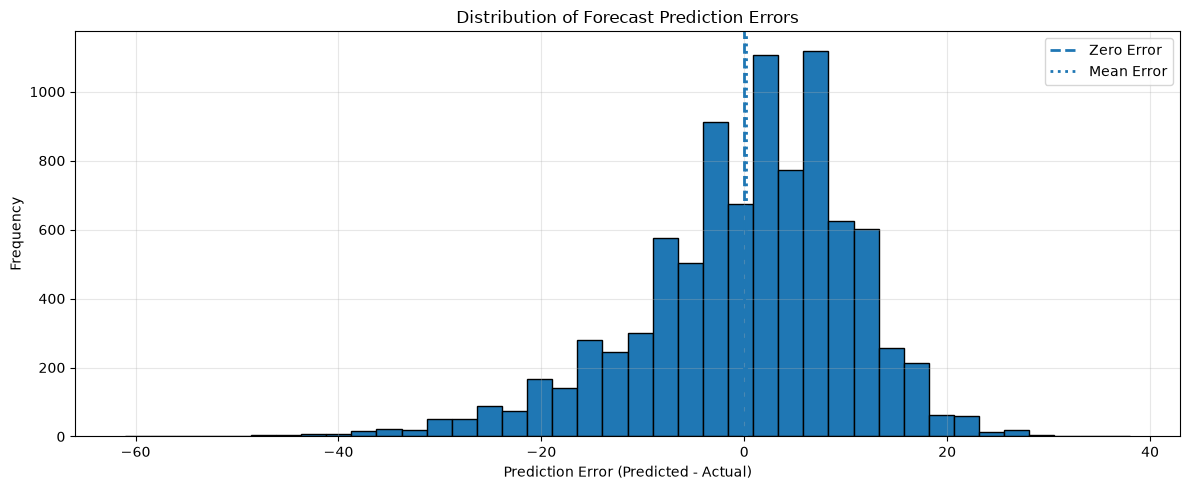

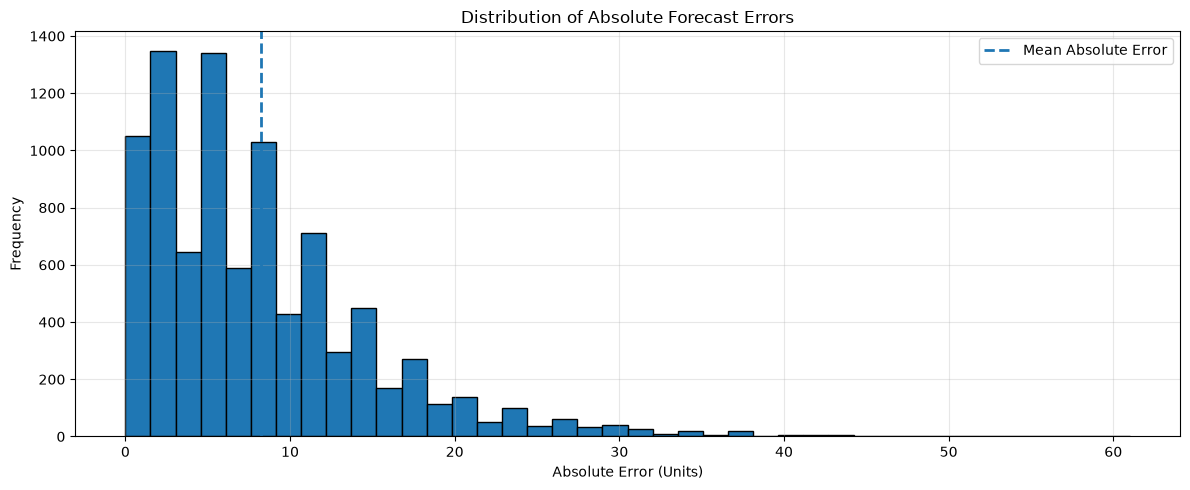

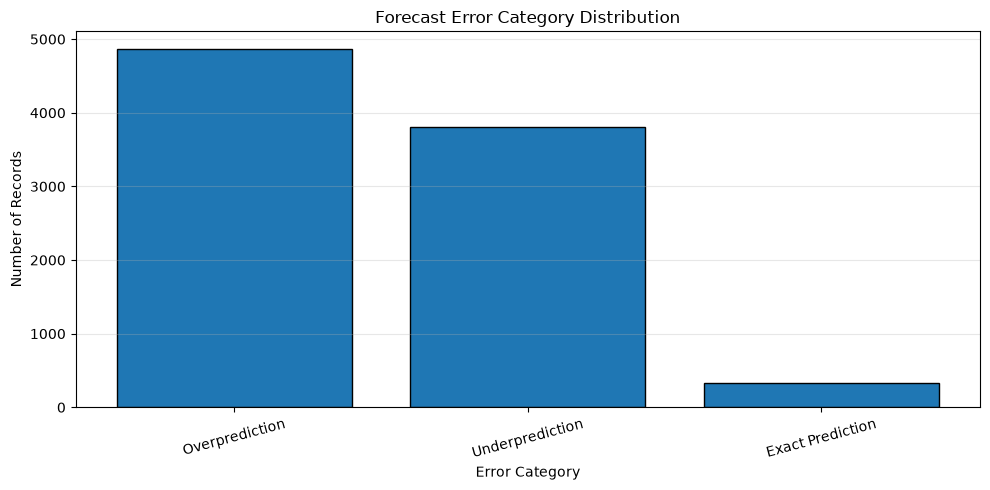

FORECAST ERROR VISUALIZATIONS COMPLETED


In [14]:

# Section 5.2: Forecast Error Distribution Visualizations

# --------------------------------------------------
# Visualization 1: Prediction Error Distribution
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.hist(
    forecast_error_analysis["prediction_error"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.axvline(
    forecast_error_analysis["prediction_error"].mean(),
    linestyle=":",
    linewidth=2,
    label="Mean Error"
)

plt.title("Distribution of Forecast Prediction Errors")
plt.xlabel("Prediction Error (Predicted - Actual)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Absolute Error Distribution
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.hist(
    forecast_error_analysis["absolute_error"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    forecast_error_analysis["absolute_error"].mean(),
    linestyle="--",
    linewidth=2,
    label="Mean Absolute Error"
)

plt.title("Distribution of Absolute Forecast Errors")
plt.xlabel("Absolute Error (Units)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 3: Error Category Distribution
# --------------------------------------------------

error_counts = (
    forecast_error_analysis["error_type"]
    .value_counts()
    .reindex([
        "Overprediction",
        "Underprediction",
        "Exact Prediction"
    ])
)

plt.figure(figsize=(10, 5))

plt.bar(
    error_counts.index,
    error_counts.values,
    edgecolor="black"
)

plt.title("Forecast Error Category Distribution")
plt.xlabel("Error Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("FORECAST ERROR VISUALIZATIONS COMPLETED")


SMARTSERVE — FORECAST PERFORMANCE BY DEMAND LEVEL
    demand_level  total_records  average_actual_demand  average_predicted_demand  mean_absolute_error  mean_prediction_error
      Low Demand           2391                  15.31                     22.42                 7.45                   7.11
   Medium Demand           4134                  29.57                     31.48                 6.08                   1.92
     High Demand           1801                  48.96                     42.96                 9.97                  -6.00
Very High Demand            674                  73.66                     54.74                19.31                 -18.92


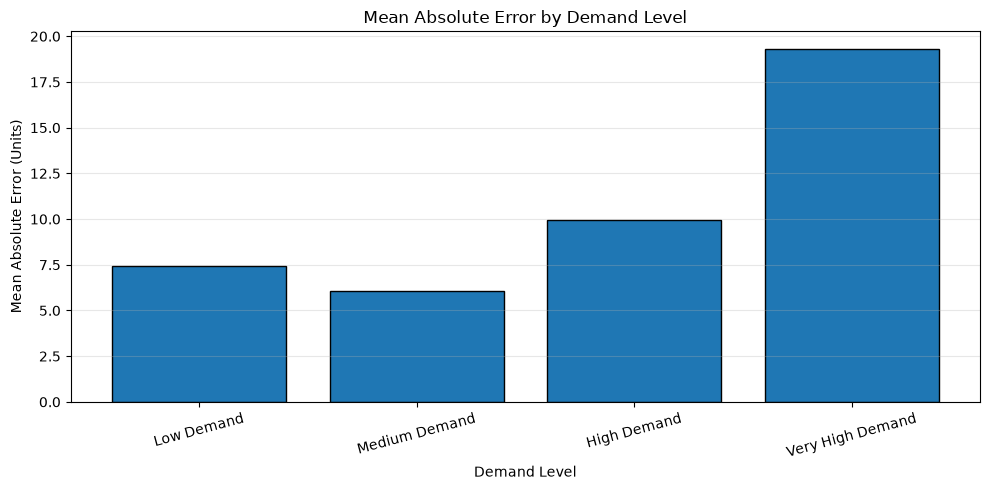


DEMAND LEVEL PERFORMANCE ANALYSIS COMPLETED


In [15]:

# Section 5.3: Forecast Error by Demand Level

# Create demand categories based on actual sales quantity
forecast_error_analysis["demand_level"] = pd.cut(
    forecast_error_analysis["actual_sales_qty"],
    bins=[-1, 20, 40, 60, float("inf")],
    labels=[
        "Low Demand",
        "Medium Demand",
        "High Demand",
        "Very High Demand"
    ]
)

# Calculate performance by demand category
demand_level_performance = (
    forecast_error_analysis
    .groupby("demand_level", observed=False)
    .agg(
        total_records=("actual_sales_qty", "count"),
        average_actual_demand=("actual_sales_qty", "mean"),
        average_predicted_demand=("predicted_sales_qty", "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_prediction_error=("prediction_error", "mean")
    )
    .reset_index()
)

print("SMARTSERVE — FORECAST PERFORMANCE BY DEMAND LEVEL")
print("=" * 85)

print(
    demand_level_performance.round(2).to_string(index=False)
)

# Visualize MAE by demand level
plt.figure(figsize=(10, 5))

plt.bar(
    demand_level_performance["demand_level"].astype(str),
    demand_level_performance["mean_absolute_error"],
    edgecolor="black"
)

plt.title("Mean Absolute Error by Demand Level")
plt.xlabel("Demand Level")
plt.ylabel("Mean Absolute Error (Units)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDEMAND LEVEL PERFORMANCE ANALYSIS COMPLETED")


In [16]:

# Section 6.1: Store Forecasting Performance Analysis

store_analysis = store_performance.copy()

# Rank stores by forecasting error
store_analysis = store_analysis.sort_values(
    "mean_absolute_error",
    ascending=True
).reset_index(drop=True)

store_analysis["performance_rank"] = (
    store_analysis.index + 1
)

print("SMARTSERVE — STORE FORECASTING PERFORMANCE")
print("=" * 85)

display(
    store_analysis[
        [
            "store_id",
            "total_records",
            "actual_demand",
            "predicted_demand",
            "mean_absolute_error",
            "mean_prediction_error",
            "demand_difference_pct",
            "performance_rank"
        ]
    ].round(2)
)

# Identify best and worst performing stores
best_store = store_analysis.iloc[0]
worst_store = store_analysis.iloc[-1]

print("\nBEST PERFORMING STORE")
print("Store:", best_store["store_id"])
print("MAE:", round(best_store["mean_absolute_error"], 2))

print("\nWORST PERFORMING STORE")
print("Store:", worst_store["store_id"])
print("MAE:", round(worst_store["mean_absolute_error"], 2))

print("\nSTORE PERFORMANCE ANALYSIS COMPLETED")


SMARTSERVE — STORE FORECASTING PERFORMANCE


,store_id,total_records,actual_demand,predicted_demand,mean_absolute_error,mean_prediction_error,demand_difference_pct,performance_rank
0,ST003,1800,41423,45439,6.37,2.23,9.70,1
1,ST002,1800,55357,55824,7.46,0.26,0.84,2
2,ST005,1800,55222,55777,7.62,0.31,1.01,3
3,ST001,1800,71927,70149,9.55,-0.99,-2.47,4
4,ST004,1800,72734,70820,10.05,-1.06,-2.63,5



BEST PERFORMING STORE
Store: ST003
MAE: 6.37

WORST PERFORMING STORE
Store: ST004
MAE: 10.05

STORE PERFORMANCE ANALYSIS COMPLETED


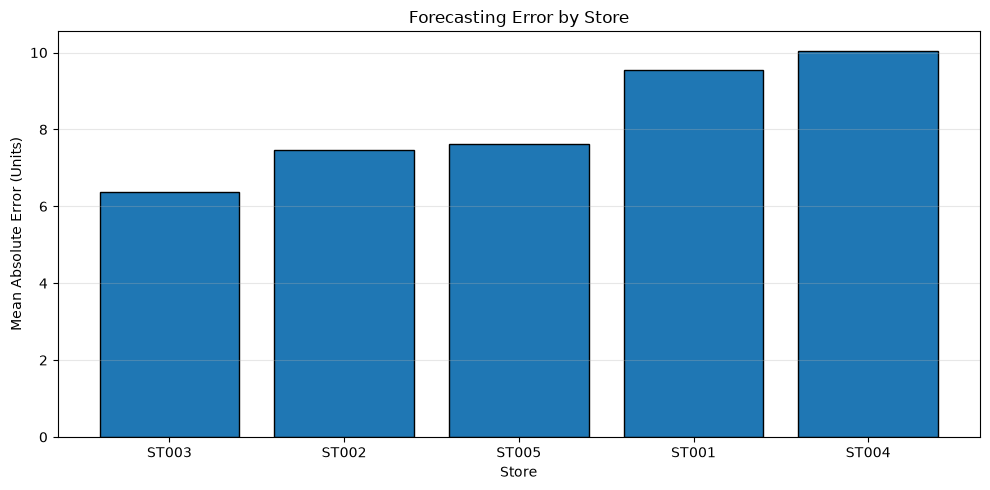

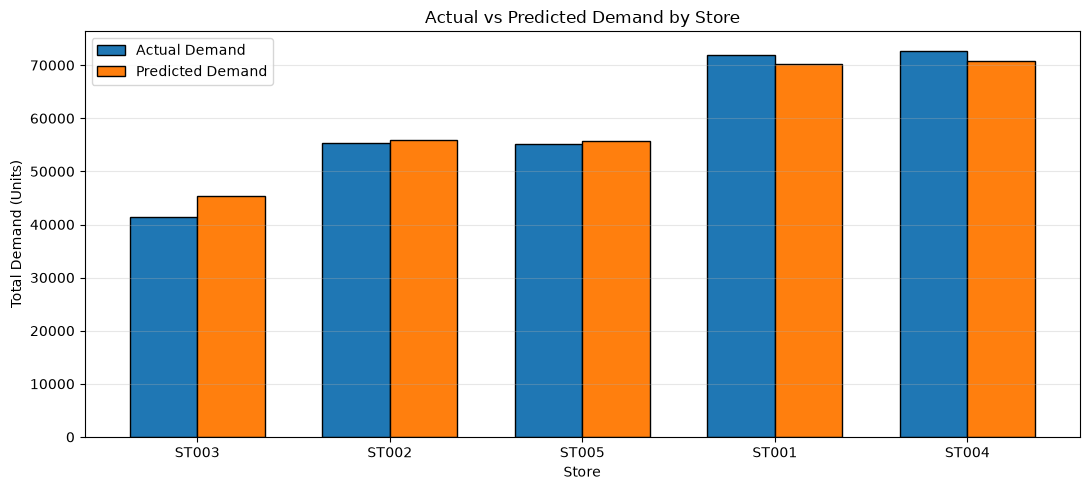

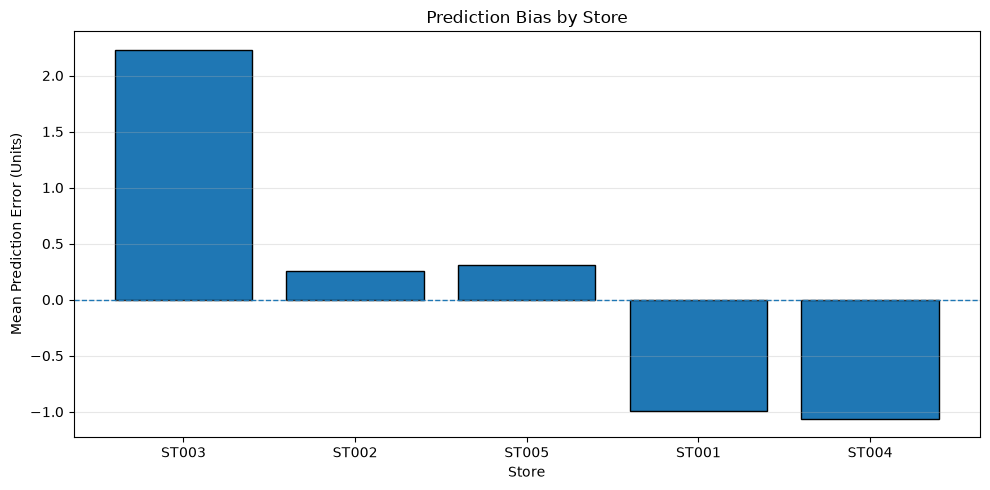

STORE PERFORMANCE VISUALIZATIONS COMPLETED


In [17]:

# Section 6.2: Store Performance Visualizations

# --------------------------------------------------
# Visualization 1: MAE by Store
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    store_analysis["store_id"],
    store_analysis["mean_absolute_error"],
    edgecolor="black"
)

plt.title("Forecasting Error by Store")
plt.xlabel("Store")
plt.ylabel("Mean Absolute Error (Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Actual vs Predicted Demand
# --------------------------------------------------

x = np.arange(len(store_analysis))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    store_analysis["actual_demand"],
    width,
    label="Actual Demand",
    edgecolor="black"
)

plt.bar(
    x + width / 2,
    store_analysis["predicted_demand"],
    width,
    label="Predicted Demand",
    edgecolor="black"
)

plt.xticks(x, store_analysis["store_id"])
plt.title("Actual vs Predicted Demand by Store")
plt.xlabel("Store")
plt.ylabel("Total Demand (Units)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 3: Mean Prediction Error by Store
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    store_analysis["store_id"],
    store_analysis["mean_prediction_error"],
    edgecolor="black"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Prediction Bias by Store")
plt.xlabel("Store")
plt.ylabel("Mean Prediction Error (Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("STORE PERFORMANCE VISUALIZATIONS COMPLETED")


In [18]:

# Section 7.1: Product Forecasting Performance Analysis

product_analysis = product_performance.copy()

# Rank products by forecasting error
product_analysis = product_analysis.sort_values(
    "mean_absolute_error",
    ascending=True
).reset_index(drop=True)

product_analysis["performance_rank"] = (
    product_analysis.index + 1
)

print("SMARTSERVE — PRODUCT FORECASTING PERFORMANCE")
print("=" * 90)

display(
    product_analysis[
        [
            "product_id",
            "total_records",
            "actual_demand",
            "predicted_demand",
            "mean_absolute_error",
            "mean_prediction_error",
            "demand_difference_pct",
            "performance_rank"
        ]
    ].round(2)
)

# Identify best and worst performing products
best_product = product_analysis.iloc[0]
worst_product = product_analysis.iloc[-1]

print("\nBEST PERFORMING PRODUCT")
print("Product:", best_product["product_id"])
print("MAE:", round(best_product["mean_absolute_error"], 2))

print("\nWORST PERFORMING PRODUCT")
print("Product:", worst_product["product_id"])
print("MAE:", round(worst_product["mean_absolute_error"], 2))

print("\nPRODUCT PERFORMANCE ANALYSIS COMPLETED")


SMARTSERVE — PRODUCT FORECASTING PERFORMANCE


,product_id,total_records,actual_demand,predicted_demand,mean_absolute_error,mean_prediction_error,demand_difference_pct,performance_rank
0,PRD016,450,7651,8976,5.51,2.94,17.32,1
1,PRD017,450,7723,9042,5.52,2.93,17.08,2
2,PRD020,450,9847,10531,5.84,1.52,6.95,3
3,PRD019,450,9735,10703,6.17,2.15,9.94,4
4,PRD018,450,9497,10592,6.22,2.43,11.53,5
5,PRD010,450,9633,11003,6.56,3.04,14.22,6
6,PRD009,450,11828,12662,6.88,1.85,7.05,7
7,PRD011,450,11877,12401,6.91,1.16,4.41,8
8,PRD014,450,11606,12439,7.06,1.85,7.18,9
9,PRD013,450,13720,13587,7.25,-0.30,-0.97,10



BEST PERFORMING PRODUCT
Product: PRD016
MAE: 5.51

WORST PERFORMING PRODUCT
Product: PRD001
MAE: 11.57

PRODUCT PERFORMANCE ANALYSIS COMPLETED


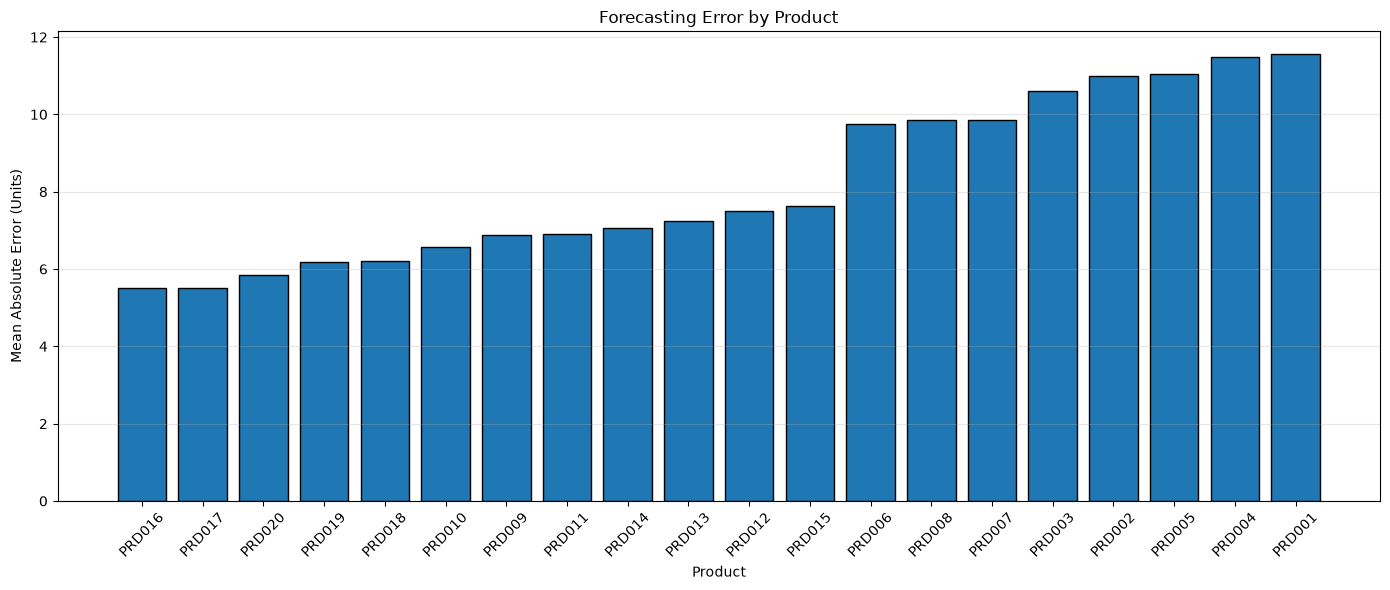

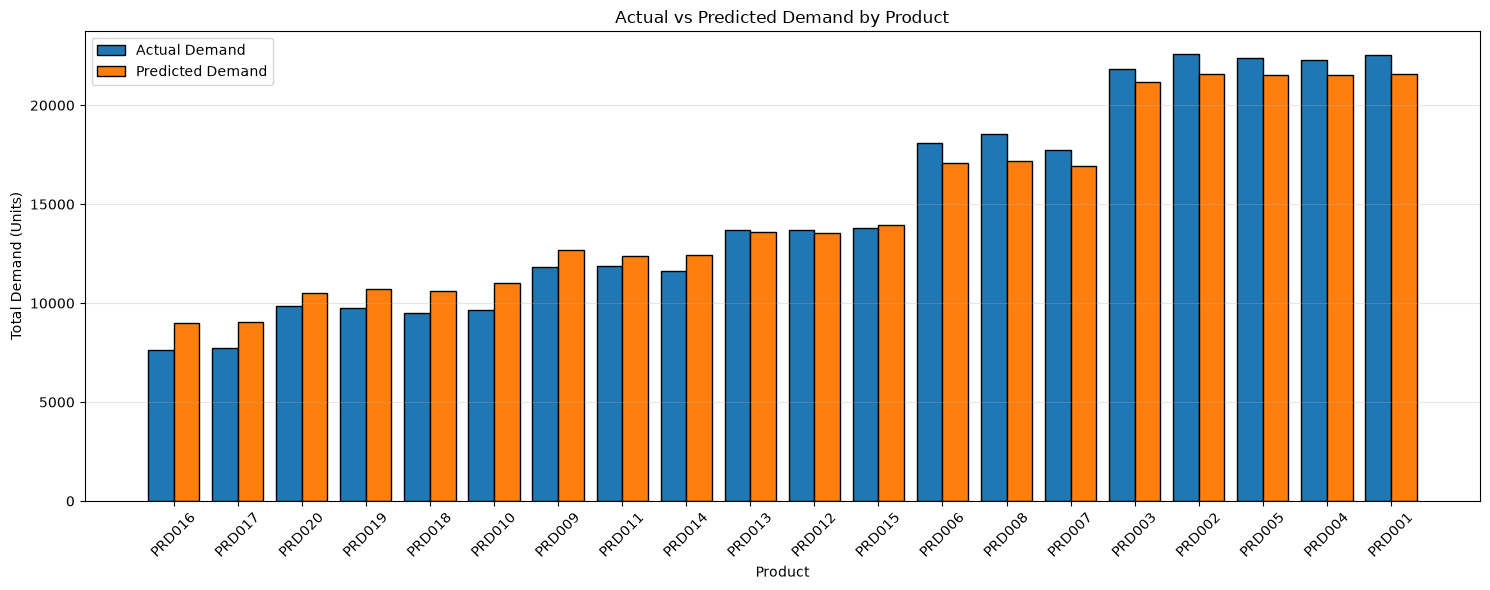

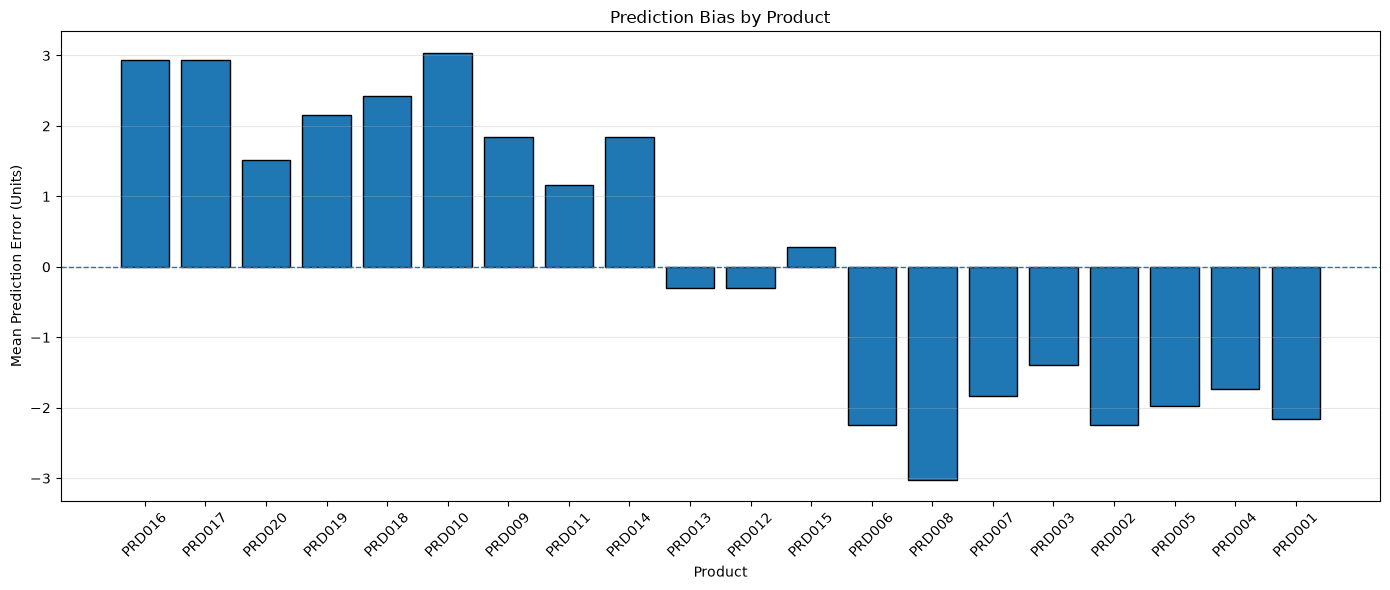

PRODUCT PERFORMANCE VISUALIZATIONS COMPLETED


In [19]:

# Section 7.2: Product Performance Visualizations

# --------------------------------------------------
# Visualization 1: MAE by Product
# --------------------------------------------------

plt.figure(figsize=(14, 6))

plt.bar(
    product_analysis["product_id"],
    product_analysis["mean_absolute_error"],
    edgecolor="black"
)

plt.title("Forecasting Error by Product")
plt.xlabel("Product")
plt.ylabel("Mean Absolute Error (Units)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Actual vs Predicted Demand
# --------------------------------------------------

x = np.arange(len(product_analysis))
width = 0.4

plt.figure(figsize=(15, 6))

plt.bar(
    x - width / 2,
    product_analysis["actual_demand"],
    width,
    label="Actual Demand",
    edgecolor="black"
)

plt.bar(
    x + width / 2,
    product_analysis["predicted_demand"],
    width,
    label="Predicted Demand",
    edgecolor="black"
)

plt.xticks(
    x,
    product_analysis["product_id"],
    rotation=45
)

plt.title("Actual vs Predicted Demand by Product")
plt.xlabel("Product")
plt.ylabel("Total Demand (Units)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 3: Prediction Bias by Product
# --------------------------------------------------

plt.figure(figsize=(14, 6))

plt.bar(
    product_analysis["product_id"],
    product_analysis["mean_prediction_error"],
    edgecolor="black"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Prediction Bias by Product")
plt.xlabel("Product")
plt.ylabel("Mean Prediction Error (Units)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("PRODUCT PERFORMANCE VISUALIZATIONS COMPLETED")


In [20]:

# Section 8.1: Inventory Recommendation Analysis

inventory_analysis = inventory_recommendations.copy()

# Calculate inventory recommendation statistics
inventory_summary = {
    "Total Store-Product Combinations": len(inventory_analysis),
    "Average Daily Demand": (
        inventory_analysis["average_daily_demand"].mean()
    ),
    "Average Maximum Predicted Demand": (
        inventory_analysis["maximum_predicted_demand"].mean()
    ),
    "Average Safety Stock": (
        inventory_analysis["safety_stock"].mean()
    ),
    "Average Recommended Stock": (
        inventory_analysis["recommended_stock"].mean()
    ),
    "Minimum Recommended Stock": (
        inventory_analysis["recommended_stock"].min()
    ),
    "Maximum Recommended Stock": (
        inventory_analysis["recommended_stock"].max()
    )
}

print("SMARTSERVE — INVENTORY DECISION SUPPORT")
print("=" * 85)

print("\nINVENTORY SUMMARY")
for metric, value in inventory_summary.items():
    print(f"{metric}: {value:,.2f}")

# Inspect highest and lowest stock recommendations
highest_stock = inventory_analysis.loc[
    inventory_analysis["recommended_stock"].idxmax()
]

lowest_stock = inventory_analysis.loc[
    inventory_analysis["recommended_stock"].idxmin()
]

print("\nHIGHEST STOCK RECOMMENDATION")
print("Store:", highest_stock["store_id"])
print("Product:", highest_stock["product_id"])
print("Recommended stock:", highest_stock["recommended_stock"])

print("\nLOWEST STOCK RECOMMENDATION")
print("Store:", lowest_stock["store_id"])
print("Product:", lowest_stock["product_id"])
print("Recommended stock:", lowest_stock["recommended_stock"])

print("\nINVENTORY RECOMMENDATION ANALYSIS COMPLETED")


SMARTSERVE — INVENTORY DECISION SUPPORT

INVENTORY SUMMARY
Total Store-Product Combinations: 100.00
Average Daily Demand: 33.11
Average Maximum Predicted Demand: 44.78
Average Safety Stock: 10.28
Average Recommended Stock: 43.92
Minimum Recommended Stock: 20.00
Maximum Recommended Stock: 82.00

HIGHEST STOCK RECOMMENDATION
Store: ST004
Product: PRD005
Recommended stock: 82

LOWEST STOCK RECOMMENDATION
Store: ST003
Product: PRD016
Recommended stock: 20

INVENTORY RECOMMENDATION ANALYSIS COMPLETED


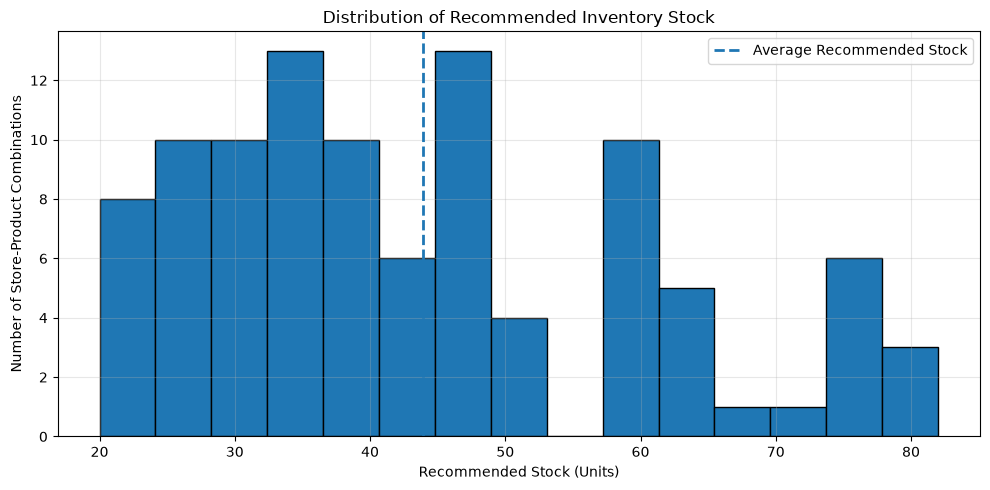

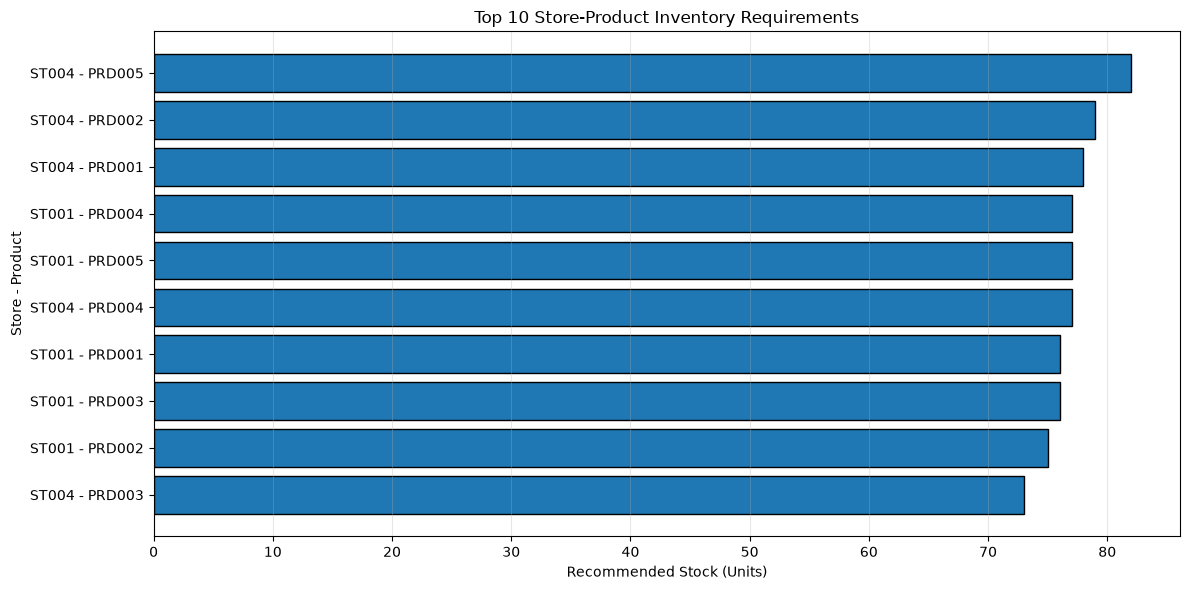

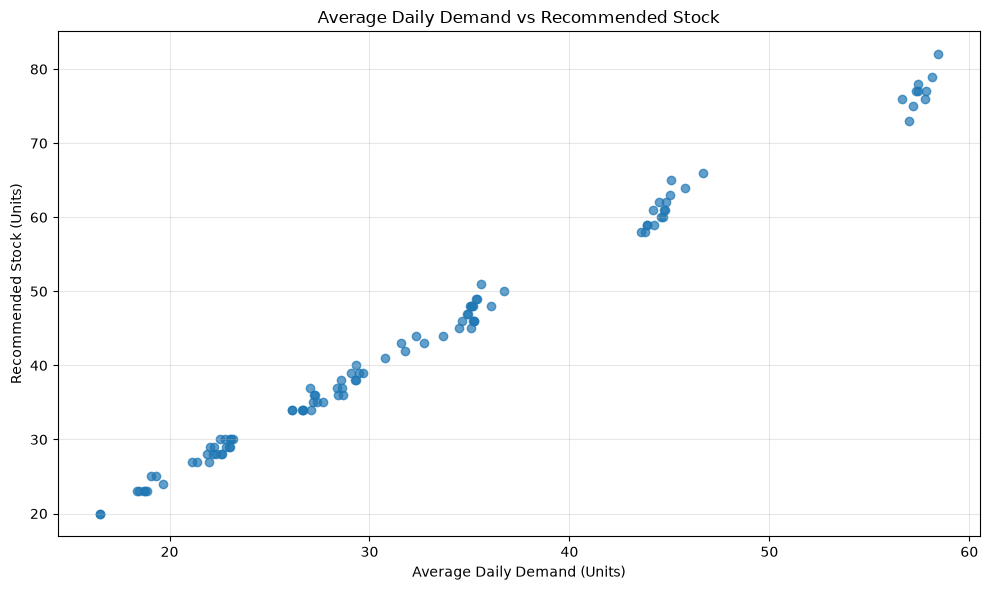

INVENTORY RECOMMENDATION VISUALIZATIONS COMPLETED


In [21]:

# Section 8.2: Inventory Recommendation Visualizations

# --------------------------------------------------
# Visualization 1: Recommended Stock Distribution
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    inventory_analysis["recommended_stock"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    inventory_analysis["recommended_stock"].mean(),
    linestyle="--",
    linewidth=2,
    label="Average Recommended Stock"
)

plt.title("Distribution of Recommended Inventory Stock")
plt.xlabel("Recommended Stock (Units)")
plt.ylabel("Number of Store-Product Combinations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Top 10 Stock Requirements
# --------------------------------------------------

top_stock_requirements = (
    inventory_analysis
    .nlargest(10, "recommended_stock")
    .copy()
)

top_stock_requirements["store_product"] = (
    top_stock_requirements["store_id"]
    + " - "
    + top_stock_requirements["product_id"]
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_stock_requirements["store_product"],
    top_stock_requirements["recommended_stock"],
    edgecolor="black"
)

plt.title("Top 10 Store-Product Inventory Requirements")
plt.xlabel("Recommended Stock (Units)")
plt.ylabel("Store - Product")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 3: Demand vs Recommended Stock
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    inventory_analysis["average_daily_demand"],
    inventory_analysis["recommended_stock"],
    alpha=0.7
)

plt.title("Average Daily Demand vs Recommended Stock")
plt.xlabel("Average Daily Demand (Units)")
plt.ylabel("Recommended Stock (Units)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("INVENTORY RECOMMENDATION VISUALIZATIONS COMPLETED")


In [22]:

# Section 8.3: Inventory Risk Analysis

inventory_risk = inventory_analysis.copy()

# Classify inventory risk using average underprediction
inventory_risk["inventory_risk_level"] = np.select(
    [
        inventory_risk["average_underprediction"] > 5,
        inventory_risk["average_underprediction"] > 2
    ],
    [
        "High Risk",
        "Medium Risk"
    ],
    default="Low Risk"
)

# Summarize risk distribution
risk_summary = (
    inventory_risk["inventory_risk_level"]
    .value_counts()
    .reindex(
        ["High Risk", "Medium Risk", "Low Risk"],
        fill_value=0
    )
    .reset_index()
)

risk_summary.columns = [
    "risk_level",
    "store_product_combinations"
]

print("SMARTSERVE — INVENTORY RISK ANALYSIS")
print("=" * 85)

print("\nRISK LEVEL DISTRIBUTION")
print(risk_summary.to_string(index=False))

# Identify highest-risk combinations
high_risk_combinations = (
    inventory_risk[
        inventory_risk["inventory_risk_level"] == "High Risk"
    ]
    .sort_values(
        "average_underprediction",
        ascending=False
    )
)

print("\nTOP 10 HIGH-RISK STORE-PRODUCT COMBINATIONS")

display(
    high_risk_combinations[
        [
            "store_id",
            "product_id",
            "average_daily_demand",
            "average_underprediction",
            "underprediction_std",
            "safety_stock",
            "recommended_stock",
            "inventory_risk_level"
        ]
    ].head(10).round(2)
)

print("\nINVENTORY RISK ANALYSIS COMPLETED")


SMARTSERVE — INVENTORY RISK ANALYSIS

RISK LEVEL DISTRIBUTION
 risk_level  store_product_combinations
  High Risk                          33
Medium Risk                          41
   Low Risk                          26

TOP 10 HIGH-RISK STORE-PRODUCT COMBINATIONS


,store_id,product_id,average_daily_demand,average_underprediction,underprediction_std,safety_stock,recommended_stock,inventory_risk_level
65,ST004,PRD006,46.68,9.97,11.15,19.0,66,High Risk
64,ST004,PRD005,58.43,9.43,13.52,23.0,82,High Risk
67,ST004,PRD008,45.80,9.37,10.91,18.0,64,High Risk
66,ST004,PRD007,45.10,9.34,11.27,19.0,65,High Risk
7,ST001,PRD008,45.03,8.68,10.08,17.0,63,High Risk
4,ST001,PRD005,57.41,8.64,11.03,19.0,77,High Risk
5,ST001,PRD006,44.81,8.54,10.19,17.0,62,High Risk
61,ST004,PRD002,58.14,8.50,12.10,20.0,79,High Risk
60,ST004,PRD001,57.42,8.13,11.69,20.0,78,High Risk
0,ST001,PRD001,57.76,8.12,10.72,18.0,76,High Risk



INVENTORY RISK ANALYSIS COMPLETED


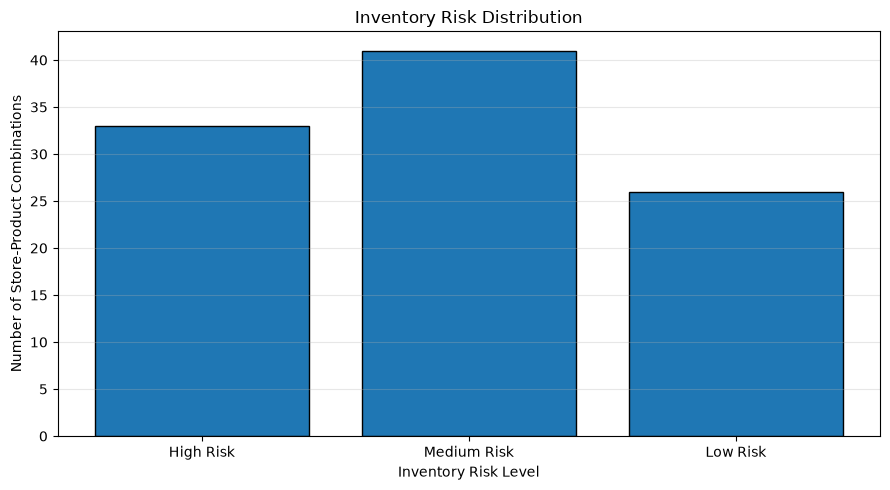

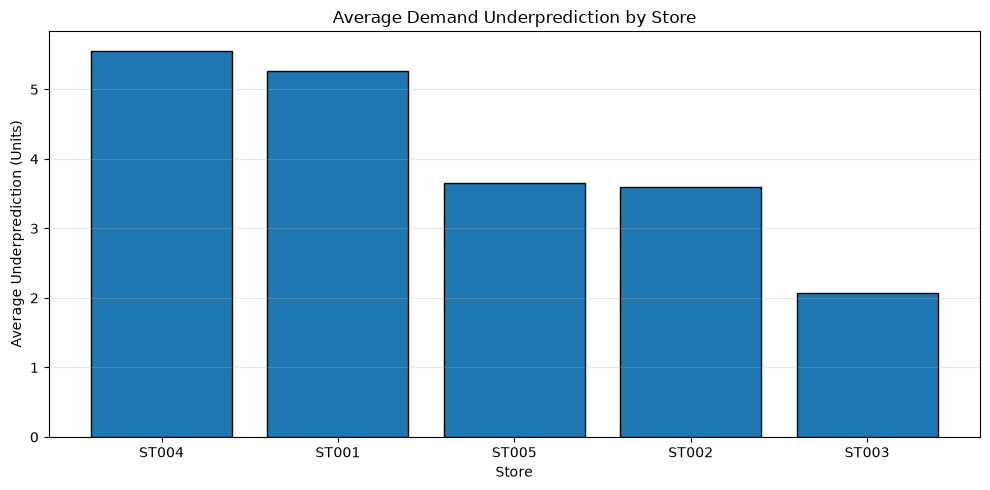

STORE-LEVEL INVENTORY RISK SUMMARY


,store_id,average_underprediction,average_safety_stock,high_risk_combinations
3,ST004,5.56,13.30,10
0,ST001,5.27,12.55,10
4,ST005,3.66,9.60,7
1,ST002,3.60,9.55,6
2,ST003,2.07,6.40,0



INVENTORY RISK VISUALIZATIONS COMPLETED


In [23]:

# Section 8.4: Inventory Risk Visualizations

# --------------------------------------------------
# Visualization 1: Inventory Risk Distribution
# --------------------------------------------------

risk_order = ["High Risk", "Medium Risk", "Low Risk"]

risk_counts = (
    inventory_risk["inventory_risk_level"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

plt.figure(figsize=(9, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values,
    edgecolor="black"
)

plt.title("Inventory Risk Distribution")
plt.xlabel("Inventory Risk Level")
plt.ylabel("Number of Store-Product Combinations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Visualization 2: Average Underprediction by Store
# --------------------------------------------------

store_inventory_risk = (
    inventory_risk
    .groupby("store_id", as_index=False)
    .agg(
        average_underprediction=(
            "average_underprediction", "mean"
        ),
        average_safety_stock=("safety_stock", "mean"),
        high_risk_combinations=(
            "inventory_risk_level",
            lambda x: (x == "High Risk").sum()
        )
    )
    .sort_values(
        "average_underprediction",
        ascending=False
    )
)

plt.figure(figsize=(10, 5))

plt.bar(
    store_inventory_risk["store_id"],
    store_inventory_risk["average_underprediction"],
    edgecolor="black"
)

plt.title("Average Demand Underprediction by Store")
plt.xlabel("Store")
plt.ylabel("Average Underprediction (Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("STORE-LEVEL INVENTORY RISK SUMMARY")
display(store_inventory_risk.round(2))

print("\nINVENTORY RISK VISUALIZATIONS COMPLETED")


In [26]:

# Section 9.1: Business Insights and Recommendations

print("SMARTSERVE — KEY BUSINESS INSIGHTS")
print("=" * 90)

# --------------------------------------------------
# 1. Overall Forecasting Performance
# --------------------------------------------------

actual = forecast_results["actual_sales_qty"]
predicted = forecast_results["predicted_sales_qty"]

overall_mae = np.mean(np.abs(actual - predicted))
overall_rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print("\n1. OVERALL FORECASTING PERFORMANCE")
print(f"Mean Absolute Error: {overall_mae:.2f}")
print(f"Root Mean Squared Error: {overall_rmse:.2f}")

# --------------------------------------------------
# 2. Demand-Level Forecasting Insights
# --------------------------------------------------

demand_insights = forecast_results.copy()

demand_insights["absolute_error"] = np.abs(
    demand_insights["predicted_sales_qty"]
    - demand_insights["actual_sales_qty"]
)

demand_insights["prediction_error"] = (
    demand_insights["predicted_sales_qty"]
    - demand_insights["actual_sales_qty"]
)

demand_insights["demand_level"] = pd.cut(
    demand_insights["actual_sales_qty"],
    bins=[-1, 20, 40, 60, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

demand_performance_summary = (
    demand_insights
    .groupby("demand_level", observed=False)
    .agg(
        record_count=("actual_sales_qty", "count"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_prediction_error=("prediction_error", "mean")
    )
    .reset_index()
)

print("\n2. DEMAND-LEVEL FORECASTING INSIGHTS")
display(demand_performance_summary.round(2))

# --------------------------------------------------
# 3. Store Performance Insights
# --------------------------------------------------

best_store = store_analysis.loc[
    store_analysis["mean_absolute_error"].idxmin()
]

worst_store = store_analysis.loc[
    store_analysis["mean_absolute_error"].idxmax()
]

print("\n3. STORE PERFORMANCE INSIGHTS")

print(
    f"Best-performing store: {best_store['store_id']} "
    f"(MAE: {best_store['mean_absolute_error']:.2f})"
)

print(
    f"Store requiring investigation: {worst_store['store_id']} "
    f"(MAE: {worst_store['mean_absolute_error']:.2f})"
)

# --------------------------------------------------
# 4. Product Performance Insights
# --------------------------------------------------

best_product = product_analysis.loc[
    product_analysis["mean_absolute_error"].idxmin()
]

worst_product = product_analysis.loc[
    product_analysis["mean_absolute_error"].idxmax()
]

print("\n4. PRODUCT PERFORMANCE INSIGHTS")

print(
    f"Most accurately predicted product: {best_product['product_id']} "
    f"(MAE: {best_product['mean_absolute_error']:.2f})"
)

print(
    f"Product requiring investigation: {worst_product['product_id']} "
    f"(MAE: {worst_product['mean_absolute_error']:.2f})"
)

# --------------------------------------------------
# 5. Inventory Risk Insights
# --------------------------------------------------

print("\n5. INVENTORY RISK INSIGHTS")

print(
    "High-risk combinations:",
    int((inventory_risk["inventory_risk_level"] == "High Risk").sum())
)

print(
    "Medium-risk combinations:",
    int((inventory_risk["inventory_risk_level"] == "Medium Risk").sum())
)

print(
    "Low-risk combinations:",
    int((inventory_risk["inventory_risk_level"] == "Low Risk").sum())
)

highest_risk = inventory_risk.loc[
    inventory_risk["average_underprediction"].idxmax()
]

print(
    f"Highest average underprediction: "
    f"{highest_risk['store_id']} - {highest_risk['product_id']} "
    f"({highest_risk['average_underprediction']:.2f} units)"
)

print("\nBUSINESS INSIGHT GENERATION COMPLETED")


SMARTSERVE — KEY BUSINESS INSIGHTS

1. OVERALL FORECASTING PERFORMANCE
Mean Absolute Error: 8.21
Root Mean Squared Error: 10.61

2. DEMAND-LEVEL FORECASTING INSIGHTS


,demand_level,record_count,mean_absolute_error,mean_prediction_error
0,Low,2391,7.45,7.11
1,Medium,4134,6.08,1.92
2,High,1801,9.97,-6.00
3,Very High,674,19.31,-18.92



3. STORE PERFORMANCE INSIGHTS
Best-performing store: ST003 (MAE: 6.37)
Store requiring investigation: ST004 (MAE: 10.05)

4. PRODUCT PERFORMANCE INSIGHTS
Most accurately predicted product: PRD016 (MAE: 5.51)
Product requiring investigation: PRD001 (MAE: 11.57)

5. INVENTORY RISK INSIGHTS
High-risk combinations: 33
Medium-risk combinations: 41
Low-risk combinations: 26
Highest average underprediction: ST004 - PRD006 (9.97 units)

BUSINESS INSIGHT GENERATION COMPLETED



### 9.2 Business Recommendations

Based on the historical demand analysis, forecasting performance, store-level evaluation, product-level evaluation, and inventory risk assessment, the following actions are recommended:

1. **Improve High-Demand Forecasting:** Prioritize model improvement for high and very-high-demand observations, where prediction errors are greatest.

2. **Investigate Store-Level Differences:** Review ST004's forecasting performance and investigate operational factors that may contribute to its higher prediction error. Use ST003 as a comparative benchmark.

3. **Review Product-Level Forecasting:** Investigate PRD001 and other higher-error products to identify demand patterns that may require additional features or specialized forecasting strategies.

4. **Apply Risk-Based Inventory Planning:** Prioritize the 33 high-risk store-product combinations for inventory monitoring and stock planning.

5. **Reduce Excess Inventory:** Review low-demand combinations where systematic overprediction could contribute to unnecessary stockholding and potential food waste.

6. **Monitor Forecast Accuracy Continuously:** Track MAE, RMSE, prediction bias, and demand-level errors as new sales data becomes available.

7. **Validate Inventory Policies Operationally:** Incorporate supplier lead times, replenishment frequency, actual stockout costs, and service-level targets before implementing recommendations in real stores.

**Business Impact:** These actions can help improve demand planning, reduce stockout exposure, manage excess inventory, and support more informed store-level operational decisions.


In [27]:

# Section 9.2: Business Recommendation Summary

business_recommendations = [
    {
        "Priority": "High",
        "Business_Area": "Demand Forecasting",
        "Finding": "Very high demand has the highest MAE of 19.31",
        "Recommended_Action": "Improve high-demand prediction performance"
    },
    {
        "Priority": "High",
        "Business_Area": "Store Operations",
        "Finding": "ST004 has the highest store MAE of 10.05",
        "Recommended_Action": "Investigate store-specific demand patterns"
    },
    {
        "Priority": "Medium",
        "Business_Area": "Product Forecasting",
        "Finding": "PRD001 has the highest product MAE of 11.57",
        "Recommended_Action": "Review product-specific forecasting features"
    },
    {
        "Priority": "High",
        "Business_Area": "Inventory Planning",
        "Finding": "33 store-product combinations are classified as high risk",
        "Recommended_Action": "Prioritize high-risk inventory monitoring"
    },
    {
        "Priority": "Medium",
        "Business_Area": "Waste Management",
        "Finding": "Low-demand observations show systematic overprediction",
        "Recommended_Action": "Review stockholding for low-demand products"
    },
    {
        "Priority": "High",
        "Business_Area": "Operational Monitoring",
        "Finding": "Historical predictions show varying errors across demand levels",
        "Recommended_Action": "Monitor forecasting accuracy and prediction bias"
    }
]

business_recommendations_df = pd.DataFrame(
    business_recommendations
)

print("SMARTSERVE — BUSINESS RECOMMENDATIONS")
print("=" * 90)

display(business_recommendations_df)

print("\nTOTAL RECOMMENDATIONS:", len(business_recommendations_df))
print("BUSINESS RECOMMENDATION SUMMARY COMPLETED")


SMARTSERVE — BUSINESS RECOMMENDATIONS


,Priority,Business_Area,Finding,Recommended_Action
0,High,Demand Forecasting,Very high demand has the highest MAE of 19.31,Improve high-demand prediction performance
1,High,Store Operations,ST004 has the highest store MAE of 10.05,Investigate store-specific demand patterns
2,Medium,Product Forecasting,PRD001 has the highest product MAE of 11.57,Review product-specific forecasting features
3,High,Inventory Planning,33 store-product combinations are classified a...,Prioritize high-risk inventory monitoring
4,Medium,Waste Management,Low-demand observations show systematic overpr...,Review stockholding for low-demand products
5,High,Operational Monitoring,Historical predictions show varying errors acr...,Monitor forecasting accuracy and prediction bias



TOTAL RECOMMENDATIONS: 6
BUSINESS RECOMMENDATION SUMMARY COMPLETED



### 10.1 Power BI Reporting Dataset Preparation

The objective of this section is to prepare clean, structured, and business-oriented datasets for Power BI reporting.

The reporting datasets will support:

- Executive KPI dashboards
- Daily demand monitoring
- Store-level forecasting performance
- Product-level forecasting performance
- Inventory recommendations and risk analysis
- Business recommendations and operational decision-making

All datasets will be exported in CSV format for Power BI integration.


In [28]:

# Section 10.1: Prepare Power BI Reporting Datasets

from pathlib import Path

# Create reporting output directory
reporting_dir = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "business_intelligence"
)

reporting_dir.mkdir(parents=True, exist_ok=True)

# Prepare reporting datasets
powerbi_datasets = {
    "daily_demand": daily_demand.copy(),
    "forecast_performance": forecast_error_analysis.copy(),
    "store_performance": store_analysis.copy(),
    "product_performance": product_analysis.copy(),
    "inventory_recommendations": inventory_risk.copy(),
    "business_recommendations": business_recommendations_df.copy()
}

print("SMARTSERVE — POWER BI DATASET PREPARATION")
print("=" * 90)

for dataset_name, dataset in powerbi_datasets.items():
    print(f"\n{dataset_name}")
    print("Shape:", dataset.shape)
    print("Columns:", dataset.columns.tolist())

print("\nReporting output directory:")
print(reporting_dir)

print("\nPOWER BI DATASET PREPARATION COMPLETED")


SMARTSERVE — POWER BI DATASET PREPARATION

daily_demand
Shape: (90, 6)
Columns: ['full_date', 'actual_demand', 'predicted_demand', 'prediction_error', 'actual_7day_avg', 'predicted_7day_avg']

forecast_performance
Shape: (9000, 10)
Columns: ['date_id', 'full_date', 'store_id', 'product_id', 'actual_sales_qty', 'predicted_sales_qty', 'prediction_error', 'absolute_error', 'error_type', 'demand_level']

store_performance
Shape: (5, 11)
Columns: ['store_id', 'total_records', 'actual_demand', 'predicted_demand', 'average_actual_demand', 'average_predicted_demand', 'mean_absolute_error', 'mean_prediction_error', 'demand_difference', 'demand_difference_pct', 'performance_rank']

product_performance
Shape: (20, 11)
Columns: ['product_id', 'total_records', 'actual_demand', 'predicted_demand', 'average_actual_demand', 'average_predicted_demand', 'mean_absolute_error', 'mean_prediction_error', 'demand_difference', 'demand_difference_pct', 'performance_rank']

inventory_recommendations
Shape: (100

In [29]:

# Section 10.2: Export Power BI Reporting Datasets

print("SMARTSERVE — POWER BI DATASET EXPORT")
print("=" * 90)

exported_files = []

for dataset_name, dataset in powerbi_datasets.items():

    output_path = (
        reporting_dir / f"{dataset_name}.csv"
    )

    dataset.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    exported_files.append(output_path)

    print(f"\nExported: {output_path.name}")
    print(f"Rows: {len(dataset):,}")
    print(f"Columns: {len(dataset.columns)}")

print("\nTOTAL DATASETS EXPORTED:", len(exported_files))
print("OUTPUT DIRECTORY:", reporting_dir)

print("\nPOWER BI DATASET EXPORT COMPLETED")


SMARTSERVE — POWER BI DATASET EXPORT

Exported: daily_demand.csv
Rows: 90
Columns: 6

Exported: forecast_performance.csv
Rows: 9,000
Columns: 10

Exported: store_performance.csv
Rows: 5
Columns: 11

Exported: product_performance.csv
Rows: 20
Columns: 11

Exported: inventory_recommendations.csv
Rows: 100
Columns: 9

Exported: business_recommendations.csv
Rows: 6
Columns: 4

TOTAL DATASETS EXPORTED: 6
OUTPUT DIRECTORY: d:\Data Analysis Projects\SmartServe-Food-Intelligence\data\processed\business_intelligence

POWER BI DATASET EXPORT COMPLETED


In [30]:

# Section 10.3: Validate Exported Power BI Datasets

print("SMARTSERVE — POWER BI EXPORT VALIDATION")
print("=" * 90)

validation_results = []

for dataset_name, original_dataset in powerbi_datasets.items():

    file_path = reporting_dir / f"{dataset_name}.csv"

    if not file_path.exists():
        validation_results.append({
            "Dataset": dataset_name,
            "File_Exists": False,
            "Shape_Matches": False,
            "Missing_Values": None,
            "Status": "FAILED"
        })
        continue

    exported_dataset = pd.read_csv(file_path)

    shape_matches = (
        exported_dataset.shape == original_dataset.shape
    )

    missing_values = int(
        exported_dataset.isnull().sum().sum()
    )

    status = (
        "PASSED"
        if shape_matches
        else "FAILED"
    )

    validation_results.append({
        "Dataset": dataset_name,
        "File_Exists": True,
        "Shape_Matches": shape_matches,
        "Missing_Values": missing_values,
        "Status": status
    })

validation_report = pd.DataFrame(validation_results)

display(validation_report)

print("\nTOTAL FILES VALIDATED:", len(validation_report))
print(
    "SUCCESSFUL VALIDATIONS:",
    (validation_report["Status"] == "PASSED").sum()
)

print(
    "FAILED VALIDATIONS:",
    (validation_report["Status"] == "FAILED").sum()
)

print("\nPOWER BI EXPORT VALIDATION COMPLETED")


SMARTSERVE — POWER BI EXPORT VALIDATION


,Dataset,File_Exists,Shape_Matches,Missing_Values,Status
0,daily_demand,True,True,0,PASSED
1,forecast_performance,True,True,0,PASSED
2,store_performance,True,True,0,PASSED
3,product_performance,True,True,0,PASSED
4,inventory_recommendations,True,True,0,PASSED
5,business_recommendations,True,True,0,PASSED



TOTAL FILES VALIDATED: 6
SUCCESSFUL VALIDATIONS: 6
FAILED VALIDATIONS: 0

POWER BI EXPORT VALIDATION COMPLETED



## 11. Final Business Intelligence Summary

### Project Completion

The SmartServe Business Intelligence and Decision Support workflow has successfully analyzed historical demand, evaluated forecasting performance, assessed inventory risks, and prepared reporting datasets.

### Key Results

- Analyzed 9,000 historical demand prediction records.
- Evaluated forecasting performance across 5 stores and 20 products.
- Achieved an overall historical prediction MAE of 8.21 and RMSE of 10.61.
- Identified demand-level forecasting weaknesses, particularly during very high demand.
- Evaluated 100 store-product inventory combinations.
- Classified 33 combinations as high inventory risk.
- Developed 6 actionable business recommendations.
- Prepared and validated 6 Power BI reporting datasets.

### Reporting Deliverables

The following files are available in `data/processed/business_intelligence/`:

1. `daily_demand.csv`
2. `forecast_performance.csv`
3. `store_performance.csv`
4. `product_performance.csv`
5. `inventory_recommendations.csv`
6. `business_recommendations.csv`

### Important Analytical Limitations

The predictions analyzed in this notebook cover the historical January–March 2025 dataset, including observations from both training and test periods. They should not be interpreted as independently validated future forecasts.

Inventory recommendations are preliminary estimates and require operational validation using supplier lead times, replenishment policies, and service-level targets.

### Conclusion

SmartServe demonstrates how historical sales data, machine learning, forecasting evaluation, and inventory analytics can be combined to support data-driven food retail decisions.

The prepared reporting datasets provide a foundation for executive dashboards and operational monitoring in Power BI.


In [31]:

# Section 11.1: Final Notebook Completion Validation

print("SMARTSERVE — BUSINESS INTELLIGENCE FINAL VALIDATION")
print("=" * 90)

# --------------------------------------------------
# 1. Analytical Dataset Summary
# --------------------------------------------------

print("\n1. ANALYTICAL DATASETS")

print("Historical prediction records:", len(forecast_results))
print("Stores analyzed:", forecast_results["store_id"].nunique())
print("Products analyzed:", forecast_results["product_id"].nunique())
print("Daily demand records:", len(daily_demand))
print("Inventory combinations:", len(inventory_recommendations))

# --------------------------------------------------
# 2. Forecasting Performance
# --------------------------------------------------

print("\n2. FORECASTING PERFORMANCE")

actual = forecast_results["actual_sales_qty"]
predicted = forecast_results["predicted_sales_qty"]

final_mae = np.mean(np.abs(actual - predicted))
final_rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print(f"MAE: {final_mae:.2f}")
print(f"RMSE: {final_rmse:.2f}")

# --------------------------------------------------
# 3. Inventory Risk Summary
# --------------------------------------------------

print("\n3. INVENTORY RISK SUMMARY")

risk_counts = (
    inventory_risk["inventory_risk_level"]
    .value_counts()
    .reindex(
        ["High Risk", "Medium Risk", "Low Risk"],
        fill_value=0
    )
)

print(risk_counts.to_string())

# --------------------------------------------------
# 4. Power BI Reporting Files
# --------------------------------------------------

print("\n4. POWER BI REPORTING FILES")

expected_files = [
    "daily_demand.csv",
    "forecast_performance.csv",
    "store_performance.csv",
    "product_performance.csv",
    "inventory_recommendations.csv",
    "business_recommendations.csv"
]

file_validation = []

for filename in expected_files:

    file_path = reporting_dir / filename

    exists = file_path.exists()

    file_validation.append({
        "File": filename,
        "Exists": exists,
        "Size_Bytes": (
            file_path.stat().st_size if exists else 0
        )
    })

    print(
        f"{filename}:",
        "FOUND" if exists else "MISSING"
    )

file_validation_df = pd.DataFrame(file_validation)

# --------------------------------------------------
# 5. Final Validation
# --------------------------------------------------

all_files_exist = file_validation_df["Exists"].all()

all_exports_passed = (
    validation_report["Status"].eq("PASSED").all()
)

final_status = all_files_exist and all_exports_passed

print("\n" + "=" * 90)
print("FINAL PROJECT STATUS")

print("Expected reporting files:", len(expected_files))
print(
    "Files successfully found:",
    int(file_validation_df["Exists"].sum())
)
print("All reporting files exist:", all_files_exist)
print("All export validations passed:", all_exports_passed)

print(
    "\nNOTEBOOK 07 STATUS:",
    "SUCCESSFULLY COMPLETED"
    if final_status
    else "REQUIRES REVIEW"
)

print("=" * 90)

display(file_validation_df)


SMARTSERVE — BUSINESS INTELLIGENCE FINAL VALIDATION

1. ANALYTICAL DATASETS
Historical prediction records: 9000
Stores analyzed: 5
Products analyzed: 20
Daily demand records: 90
Inventory combinations: 100

2. FORECASTING PERFORMANCE
MAE: 8.21
RMSE: 10.61

3. INVENTORY RISK SUMMARY
inventory_risk_level
High Risk      33
Medium Risk    41
Low Risk       26

4. POWER BI REPORTING FILES
daily_demand.csv: FOUND
forecast_performance.csv: FOUND
store_performance.csv: FOUND
product_performance.csv: FOUND
inventory_recommendations.csv: FOUND
business_recommendations.csv: FOUND

FINAL PROJECT STATUS
Expected reporting files: 6
Files successfully found: 6
All reporting files exist: True
All export validations passed: True

NOTEBOOK 07 STATUS: SUCCESSFULLY COMPLETED


,File,Exists,Size_Bytes
0,daily_demand.csv,True,5350
1,forecast_performance.csv,True,662516
2,store_performance.csv,True,495
3,product_performance.csv,True,1380
4,inventory_recommendations.csv,True,5251
5,business_recommendations.csv,True,780
